# Beta Bank Lost Clients

# Project Overview

The objective of this project is to predict whether a customer of Beta Bank is likely to leave the bank in the near future. Accurate predictions enable the bank to identify at-risk customers and implement retention strategies, reducing customer churn and the costs associated with acquiring new clients.

# 1. Data Preparing

## 1.1 Data Collection

In [32]:
import pandas as pd
from plotly import express as px
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils import shuffle

In [33]:
data = pd.read_csv('/datasets/Churn.csv')
data.head(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


In [35]:
# Find duplicated
print(data.duplicated().sum(), 'duplicated')

0 duplicated


**Data Obsevations:**

1. The column names are in UpperCamel format.
2. 'RowNumber' column is not neccesary beacuse the DataFrame has alredy index.
3. There are 909 null values in 'Tenure' column

In [36]:
# Function to format string with format UperCamel to snake_case
def to_snake_case(string):
    '''
    Function to format colums name to UperCamel to snake_case

    Args:
        string (str): The string to convert
   
    Returns:
        str: The string converted a snake_case format
   
    Raises:
        None

    Example:
        >>> to_snake_case('RowNumber')
        row_number
    '''

    snake_case_str = ''
    
    for letter in string:
        if letter.isupper():
            snake_case_str += '_'
        snake_case_str += letter.lower()

    # Remmove the first underscore
    if snake_case_str[0] == '_':
        snake_case_str = snake_case_str[1:]
    return snake_case_str    

In [37]:
# Convert the columns name to snake_case format
data.columns = [to_snake_case(col) for col in data.columns]

print(data.columns)

Index(['row_number', 'customer_id', 'surname', 'credit_score', 'geography',
       'gender', 'age', 'tenure', 'balance', 'num_of_products', 'has_cr_card',
       'is_active_member', 'estimated_salary', 'exited'],
      dtype='object')


In [38]:
# Drop 'row_number' column
data.drop(columns='row_number', inplace=True)

data.head()

,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
0,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


Missing values in the Tenure column were **replaced** through **random sampling** based on the observed **distribution** of tenure values. This approach preserves the original distribution and avoids introducing an artificial peak that would result from median imputation.

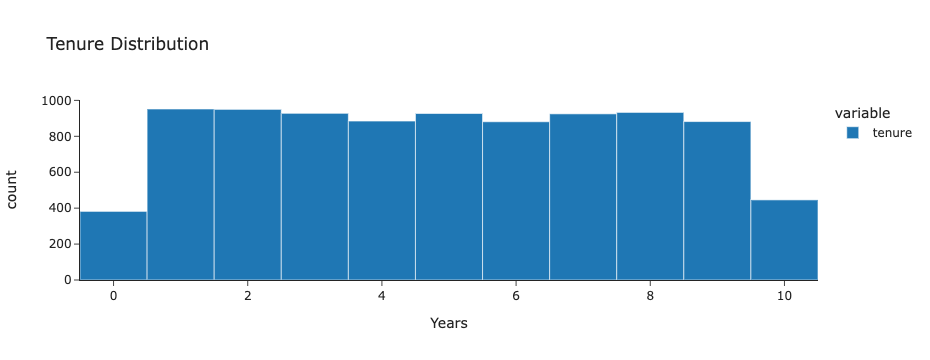

In [39]:
# Tenure distribution 
px.histogram(
    data['tenure'],
    title='Tenure Distribution',
    labels={'value':'Years'},
    template='simple_white'
)

In [40]:
# Replace null values with random sample with the same distribution
np.random.seed(12345) # The same random numbers

dist = data['tenure'].value_counts(normalize=True)

data.loc[data['tenure'].isna(), 'tenure'] = np.random.choice(
    dist.index,
    size=data['tenure'].isna().sum(),
    p=dist.values
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   surname           10000 non-null  object 
 2   credit_score      10000 non-null  int64  
 3   geography         10000 non-null  object 
 4   gender            10000 non-null  object 
 5   age               10000 non-null  int64  
 6   tenure            10000 non-null  float64
 7   balance           10000 non-null  float64
 8   num_of_products   10000 non-null  int64  
 9   has_cr_card       10000 non-null  int64  
 10  is_active_member  10000 non-null  int64  
 11  estimated_salary  10000 non-null  float64
 12  exited            10000 non-null  int64  
dtypes: float64(3), int64(7), object(3)
memory usage: 1015.8+ KB


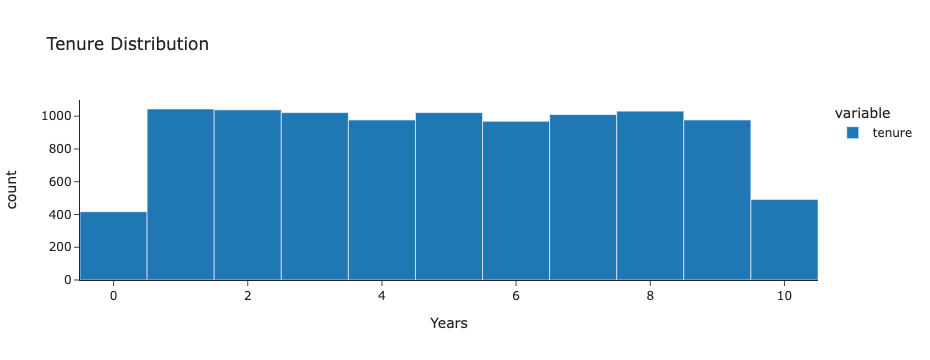

In [41]:
# Efect confirmation
data.info()

px.histogram(
    data['tenure'],
    title='Tenure Distribution',
    labels={'value':'Years'},
    template='simple_white'
)

1. The column names were replaced with snake_case format
2. 'row_number' was dropped
3. Missing values in the Tenure column were replaced through random sampling based on the observed distribution of tenure values.

## 1.2 Data Preparing

The dataset will be prepared for model training by removing irrelevant features and encoding categorical variables into numerical representations, allowing the machine learning models to process and interpret the data effectively.

In [42]:
data.head()

,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
0,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


In [43]:
# Drop irrelevant features
irrelevant_features = ['customer_id', 'surname']

m_data = data.drop(columns=irrelevant_features)

m_data.head()

,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
0,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


In [44]:
# Convert categorical varibles
m_data = pd.get_dummies(
    m_data,
    drop_first=True
)

m_data.head()

,credit_score,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited,geography_Germany,geography_Spain,gender_Male
0,619,42,2.0,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1.0,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8.0,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1.0,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2.0,125510.82,1,1,1,79084.10,0,0,1,0


In [45]:
# Scale data
target = m_data['exited'] # The target doesn´t scale
m_data = m_data.drop(columns='exited')

scaler = StandardScaler()
scaler.fit(m_data)
m_data = pd.DataFrame(scaler.transform(m_data), columns=m_data.columns)

m_data.head()

,credit_score,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,geography_Germany,geography_Spain,gender_Male
0,-0.326221,0.293517,-1.038313,-1.225848,-0.911583,0.646092,0.970243,0.021886,-0.578736,-0.573809,-1.095988
1,-0.440036,0.198164,-1.383830,0.117350,-0.911583,-1.547768,0.970243,0.216534,-0.578736,1.742740,-1.095988
2,-1.536794,0.293517,1.034789,1.333053,2.527057,0.646092,-1.030670,0.240687,-0.578736,-0.573809,-1.095988
3,0.501521,0.007457,-1.383830,-1.225848,0.807737,-1.547768,-1.030670,-0.108918,-0.578736,-0.573809,-1.095988
4,2.063884,0.388871,-1.038313,0.785728,-0.911583,0.646092,0.970243,-0.365276,-0.578736,1.742740,-1.095988



- The **ID and surname** features were **removed**, as they do not provide predictive value and are therefore irrelevant to the model.

- **Categorical** features were **converted** into numerical representations using One-Hot Encoding, allowing the machine learning models to process and interpret the data effectively.

- The data were **scaled** to ensure compatibility with algorithms that are sensitive to feature magnitudes, such as Logistic Regression. Although Decision Tree and Random Forest models do not require feature scaling, applying it does not negatively affect their performance.

# 2. Model Training

**Decision Tree, Random Forest, and Logistic Regression** models will be trained using the original **imbalanced** dataset. Their performance will then be compared with the results obtained after applying class balancing techniques to evaluate the impact of class imbalance on model performance.

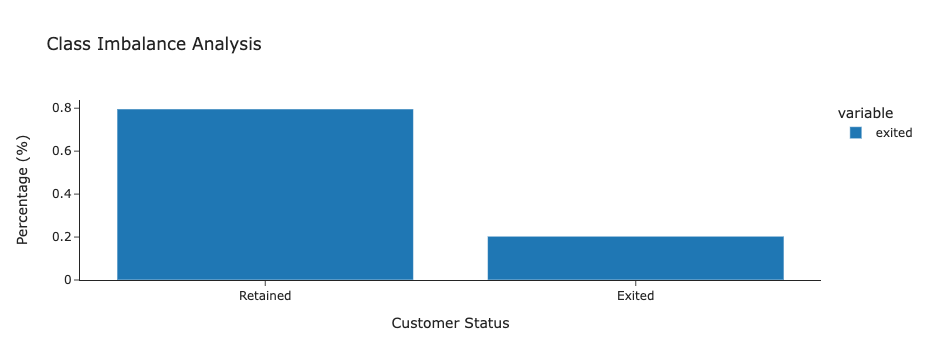

In [46]:
# Examining class imbalance
target_proportion = target.value_counts(normalize=True)
target_proportion.index = ['Retained', 'Exited']

px.bar(
    target_proportion,
    title='Class Imbalance Analysis',
    labels={
        'value': 'Percentage (%)',
        'index': 'Customer Status'
    },
    template='simple_white'
)

In [47]:
# Split data in training, valid and test data sets
features = m_data

features_train, features_evaluate, target_train, target_evaluate = train_test_split(features, target, test_size=0.40, random_state=12345)
features_valid, features_test, target_valid, target_test = train_test_split(features_evaluate, target_evaluate, test_size=0.50, random_state=12345)
print(features_train.shape)
print(features_valid.shape)
print(features_test.shape)
print(target_train.shape)
print(target_valid.shape)
print(target_test.shape)


(6000, 11)
(2000, 11)
(2000, 11)
(6000,)
(2000,)
(2000,)


In [48]:
def find_best_models(features_train, target_train, features_valid, target_valid, balanced=None):
    """
    Trains and evaluates multiple classification models using different
    hyperparameter combinations and returns the best-performing configuration
    for each model based on the F1 score.

    Models evaluated:
        - Decision Tree Classifier
        - Random Forest Classifier
        - Logistic Regression

    The function performs a simple grid search over predefined
    hyperparameter ranges and selects the configuration with the highest
    F1 score on the validation set.

    Evaluation metrics:
        - Accuracy
        - Precision
        - Recall
        - F1 Score
        - ROC-AUC

    Parameters
    ----------
    features_train : pandas.DataFrame
        Training feature set.

    target_train : pandas.Series
        Training target variable.

    features_valid : pandas.DataFrame
        Validation feature set.

    target_valid : pandas.Series
        Validation target variable.

    balanced : object, optional, defautl=None
        None for imbalanced classes or 'balanced' for balanced classes

    Returns
    -------
    tuple
        A tuple containing:

        tree_model : DecisionTreeClassifier
            Trained Decision Tree model.

        forest_model : RandomForestClassifier
            Trained Random Forest model.

        regression_model : LogisticRegression
            Trained Logistic Regression model.

        scores : pandas.DataFrame
            Summary table containing the best metrics and
            hyperparameters for each model.

    Notes
    -----
    - Decision Tree models are evaluated with max_depth values from 2 to 15.
    - Random Forest models are evaluated using different combinations
      of max_depth and n_estimators.
    - Logistic Regression models are evaluated using different values
      of C and solver.
    - Model selection is based on the highest F1 score obtained on
      the validation set.
    """
    # Decision Tree model
    scores = pd.DataFrame()
    max_depth_range = range(2,16)
    best_depth = 0
    best_scores = {'model':['Decision Tree'], 'f1':[0]}
    for depth in max_depth_range:
        # Training the model
        tree_model = DecisionTreeClassifier(max_depth=depth, class_weight=balanced, random_state=12345)
        tree_model.fit(features_train, target_train)
        predictions = tree_model.predict(features_valid)
        probabilites_one = tree_model.predict_proba(features_valid)[:,1]

        f1 = f1_score(target_valid, predictions)

        if f1 > best_scores['f1'][0]:
            # Scores
            best_scores['accuracy'] = [accuracy_score(target_valid, predictions)]
            best_scores['precision'] = [precision_score(target_valid, predictions)]
            best_scores['recall'] = [recall_score(target_valid, predictions)]
            best_scores['f1'] = [f1_score(target_valid, predictions)]
            best_scores['roc_auc'] = [roc_auc_score(target_valid, probabilites_one)]
    
            # Hyperparameters
            best_scores['depth'] = [depth]
    
    scores = pd.DataFrame(best_scores)

    # Random Forest model
    max_depth_range = range(11,14)
    n_estimators_range = range(50,151,50)
    best_depth = 0
    best_scores = {'model':['Random Forest'],'f1':[0]}
    for depth in max_depth_range:
        for n_estimators in n_estimators_range:
            # Training the model
            forest_model = RandomForestClassifier(n_estimators=n_estimators, class_weight=balanced, max_depth=depth, random_state=12345)
            forest_model.fit(features_train, target_train)
            predictions = forest_model.predict(features_valid)
            probabilites_one = forest_model.predict_proba(features_valid)[:,1]

            f1 = f1_score(target_valid, predictions)
    
            if f1 > best_scores['f1'][0]:
                # Scores
                best_scores['accuracy'] = [accuracy_score(target_valid, predictions)]
                best_scores['precision'] = [precision_score(target_valid, predictions)]
                best_scores['recall'] = [recall_score(target_valid, predictions)]
                best_scores['f1'] = [f1_score(target_valid, predictions)]
                best_scores['roc_auc'] = [roc_auc_score(target_valid, probabilites_one)]
        
                # Hyperparameters
                best_scores['depth'] = [depth]
                best_scores['estimators'] = [n_estimators]
            
    score = pd.DataFrame(best_scores)
    scores = pd.concat([scores, score]).reset_index(drop=True)

    # Logistic Regresion model
    solvers = ['liblinear', 'lbfgs']
    c_range = [0.01, 0.1, 1, 10, 100]
    best_scores = {'model':['Logistic Regression'],'f1':[0]}
    for solver in solvers:
        for c in c_range:
            # Training the model
            regression_model = LogisticRegression(solver=solver, C=c, class_weight=balanced, random_state=12345)
            regression_model.fit(features_train, target_train)
            predictions = regression_model.predict(features_valid)
            probabilites_one = regression_model.predict_proba(features_valid)[:,1]

            f1 = f1_score(target_valid, predictions)
    
            if f1 > best_scores['f1'][0]:
                # Scores
                best_scores['accuracy'] = [accuracy_score(target_valid, predictions)]
                best_scores['precision'] = [precision_score(target_valid, predictions)]
                best_scores['recall'] = [recall_score(target_valid, predictions)]
                best_scores['f1'] = [f1_score(target_valid, predictions)]
                best_scores['roc_auc'] = [roc_auc_score(target_valid, probabilites_one)]
        
                # Hyperparameters
                best_scores['C'] = [c]
                best_scores['solver'] = [solver]
                
    score = pd.DataFrame(best_scores)
    scores = pd.concat([scores, score]).reset_index(drop=True)

    # Balanced or Imbalanced
    if balanced == 'balanced':
        scores['balanced'] = 'Balanced'
    else:
        scores['balanced'] = 'Imbalanced'
    
    return tree_model, forest_model, regression_model, scores 

In [49]:
# Training the imbalaced models
tree_model, forest_model, regression_model, scores = find_best_models(features_train, target_train, features_valid, target_valid)
scores.round(3)

,model,f1,accuracy,precision,recall,roc_auc,depth,estimators,C,solver,balanced
0,Decision Tree,0.572,0.848,0.695,0.486,0.783,9.0,NaN,NaN,NaN,Imbalanced
1,Random Forest,0.590,0.866,0.818,0.462,0.846,12.0,150.0,NaN,NaN,Imbalanced
2,Logistic Regression,0.337,0.803,0.568,0.239,0.759,NaN,NaN,1.0,liblinear,Imbalanced


The dataset is **imbalanced**, with approximately `79.6%` retained customers and `20.4%` exited customers. This distribution may negatively affect the models' ability to detect churn cases, particularly by reducing recall for the minority class.

The three models were initially trained using the original imbalanced dataset to establish a baseline for comparison before applying class-balancing techniques.

The **Decision Tree** model achieved an accuracy of `0.85`, with a precision of `0.70` and a recall of `0.49`. While the model performed reasonably well overall, it failed to identify more than half of the customers who actually left the bank, resulting in a moderate F1-score of `0.57`.

The **Random Forest** model delivered the best overall performance, achieving an accuracy of `0.87`, a precision of `0.82`, an F1-score of `0.59`, and a ROC-AUC score of `0.85`. The high precision indicates that most customers predicted as churners were correctly classified. However, the recall of `0.46` suggests that a substantial portion of actual churn cases remained undetected, which is a common consequence of class imbalance.

The **Logistic Regression** model produced the weakest results, with an accuracy of `0.80`, a precision of `0.57`, and a recall of only `0.24`. These results indicate that the model struggled to identify customers who left the bank and was heavily influenced by the majority class.

# 3. Model Performing

The target classes are **imbalanced**, which may prevent the models from effectively learning the underlying patterns associated with customer churn. As a result, the models tend to favor the majority class, reducing their ability to correctly identify customers who are likely to leave the bank. To address this issue, the following **class-balancing techniques** will be applied:

- **Class weight adjustment**, to assign a higher penalty to misclassified churn cases during training.
- **Oversampling**, to increase the number of observations in the minority class.

> **Note**
>
> The **SMOTE (Synthetic Minority Oversampling Technique)** method from the `imblearn` library was initially considered to address the class imbalance problem. However, the platform's permission restrictions prevented the installation of the required package. Therefore, a standard **oversampling** approach was applied instead to balance the minority class and improve the models' ability to detect churn cases.

## 3.1 Class Weight Adjustment

In [50]:

# Training the models with balanced classes
tree_model, forest_model, regression_model, score = find_best_models(features_train, target_train, features_valid, target_valid, 'balanced')

scores = pd.concat([scores, score]).reset_index(drop=True)
scores.round(3)



,model,f1,accuracy,precision,recall,roc_auc,depth,estimators,C,solver,balanced
0,Decision Tree,0.572,0.848,0.695,0.486,0.783,9.0,NaN,NaN,NaN,Imbalanced
1,Random Forest,0.590,0.866,0.818,0.462,0.846,12.0,150.0,NaN,NaN,Imbalanced
2,Logistic Regression,0.337,0.803,0.568,0.239,0.759,NaN,NaN,1.00,liblinear,Imbalanced
3,Decision Tree,0.596,0.810,0.537,0.670,0.831,5.0,NaN,NaN,NaN,Balanced
4,Random Forest,0.614,0.847,0.650,0.581,0.851,11.0,150.0,NaN,NaN,Balanced
5,Logistic Regression,0.489,0.698,0.379,0.691,0.764,NaN,NaN,0.01,liblinear,Balanced


## 3.2 Oversampling


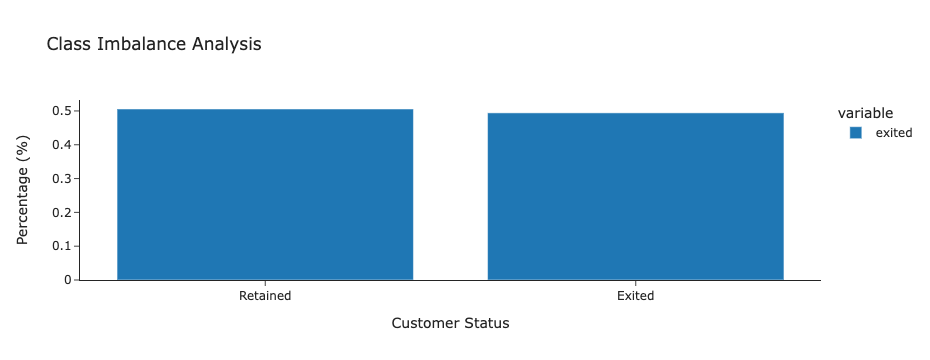

In [51]:
# Apply oversampling by replicating the minority class (Exited) four times
joined_data = pd.concat([m_data, target], axis=1)

# Separate the data in exited and no exited
joined_data_ones = joined_data[joined_data['exited'] == 1]
joined_data_zero = joined_data[joined_data['exited'] == 0]

# Multiplicated data and concatenate with zero class
joined_data_ones_x4 = pd.concat([joined_data_ones]*4).reset_index(drop=True)
joined_data = pd.concat([joined_data_ones_x4,joined_data_zero]).reset_index(drop=True)

# Shuffle
suffle_data = shuffle(joined_data, random_state=12345).reset_index(drop=True)

# Split data
features_train = suffle_data.drop(columns='exited')
target_train = suffle_data['exited']

# Examining class imbalance
target_proportion = target_train.value_counts(normalize=True)
target_proportion.index = ['Retained', 'Exited']

px.bar(
    target_proportion,
    title='Class Imbalance Analysis',
    labels={
        'value': 'Percentage (%)',
        'index': 'Customer Status'
    },
    template='simple_white'
)


In [52]:
# Training the models with Oversampling
tree_model, forest_model, regression_model, score = find_best_models(features_train, target_train, features_valid, target_valid)

score['balanced'] = 'Oversampling' 
scores = pd.concat([scores, score]).reset_index(drop=True)
scores.round(3)

,model,f1,accuracy,precision,recall,roc_auc,depth,estimators,C,solver,balanced
0,Decision Tree,0.572,0.848,0.695,0.486,0.783,9.0,NaN,NaN,NaN,Imbalanced
1,Random Forest,0.590,0.866,0.818,0.462,0.846,12.0,150.0,NaN,NaN,Imbalanced
2,Logistic Regression,0.337,0.803,0.568,0.239,0.759,NaN,NaN,1.00,liblinear,Imbalanced
3,Decision Tree,0.596,0.810,0.537,0.670,0.831,5.0,NaN,NaN,NaN,Balanced
4,Random Forest,0.614,0.847,0.650,0.581,0.851,11.0,150.0,NaN,NaN,Balanced
5,Logistic Regression,0.489,0.698,0.379,0.691,0.764,NaN,NaN,0.01,liblinear,Balanced
6,Decision Tree,0.881,0.945,0.804,0.974,0.992,15.0,NaN,NaN,NaN,Oversampling
7,Random Forest,0.914,0.962,0.860,0.974,0.995,13.0,100.0,NaN,NaN,Oversampling
8,Logistic Regression,0.495,0.706,0.386,0.691,0.768,NaN,NaN,0.01,lbfgs,Oversampling


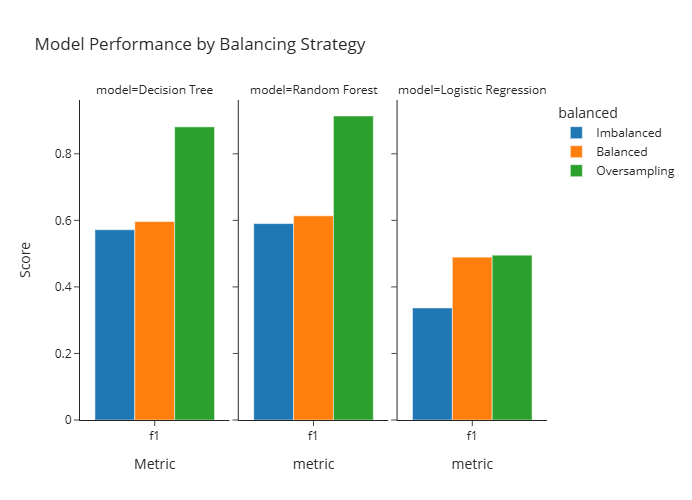

In [53]:
# Scores plot
metrics = ['f1']

scores_long = scores.melt(
    id_vars=['model', 'balanced'],
    value_vars=metrics,
    var_name='metric',
    value_name='score'
)

fig = px.bar(
    scores_long,
    x='metric',
    y='score',
    color='balanced',
    barmode='group',
    facet_col='model',
    title='Model Performance by Balancing Strategy',
    template='simple_white'
)

fig.update_layout(
    height=500,
    yaxis_title='Score',
    xaxis_title='Metric'
)

fig.show()

**Findings**

After applying class weight balancing, all models improved their recall considerably. The **Decision Tree recall** increased from `0.49` to `0.67`, the **Random Forest recall** increased from `0.46` to `0.58`, and **Logistic Regression** achieved the largest improvement, increasing from `0.24` to `0.69`. These gains came at the cost of lower accuracy and precision, which is expected when the model places greater emphasis on the minority class.

The most substantial improvement was obtained through **oversampling**. Both tree-based models achieved exceptionally high recall values of `0.97`, meaning that almost all churn cases were correctly identified. In addition, oversampling produced the highest F1-scores and ROC-AUC values across all experiments. The **Random Forest with oversampling** (Hyperparameters: `max_depth=13, n_estimators=100`) delivered the best overall performance, achieving:

- Accuracy: `0.96`
- Precision: `0.86`
- Recall: `0.97`
- F1-score: `0.91`
- ROC-AUC: `0.99`

# 4. Final Test

Based on the previous results, the **Random Forest** model was selected as the final candidate due to its superior performance after applying oversampling. The model will be **trained** using the balanced training dataset with `max_depth=13` and `n_estimators=100`. Predictions will then be generated on the **test set**, and the model's performance will be assessed using the selected evaluation metrics to determine its effectiveness in identifying customer churn.

In [54]:

# Training the model
forest_model = RandomForestClassifier(n_estimators=100, max_depth=13, random_state=12345)
forest_model.fit(features_train, target_train)
predictions = forest_model.predict(features_test)
probabilites_one = forest_model.predict_proba(features_test)[:,1]

# Test set scores
test_score = pd.DataFrame({
    'model':['Random Forest'],
    'f1':[f1_score(target_test, predictions)],
    'accuracy':[accuracy_score(target_test, predictions)],
    'precision':[precision_score(target_test, predictions)],
    'recall':[recall_score(target_test, predictions)],
    'roc_auc':[roc_auc_score(target_test, probabilites_one)],
    'set':['Test']
})


# Valid set scores
valid_score = pd.DataFrame(scores.iloc[7]).T[['model','f1','accuracy','precision','recall','roc_auc']]
valid_score['set'] = 'Valid'

# Scores comparation
final_scores = pd.concat([test_score, valid_score]).reset_index(drop=True)
final_scores[['f1','accuracy','precision','recall','roc_auc']] = final_scores[['f1','accuracy','precision','recall','roc_auc']].astype('float')
final_scores.round(3)

,model,f1,accuracy,precision,recall,roc_auc,set
0,Random Forest,0.929,0.968,0.886,0.976,0.996,Test
1,Random Forest,0.914,0.962,0.860,0.974,0.995,Valid


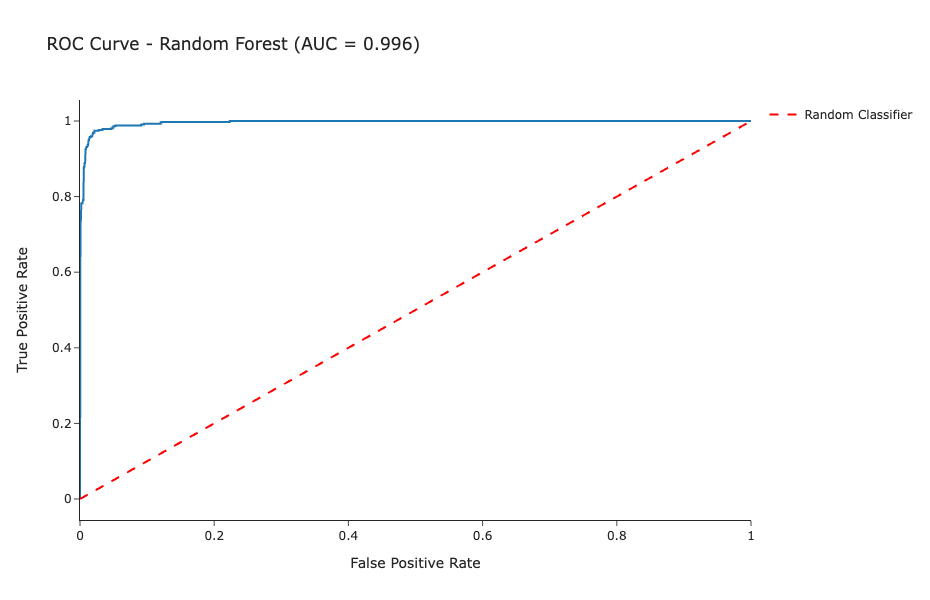

In [55]:
# ROC curve values
fpr, tpr, thresholds = roc_curve(target_test, probabilites_one)

roc_df = pd.DataFrame({
    'False Positive Rate': fpr,
    'True Positive Rate': tpr
})

# ROC-AUC score
roc_auc = roc_auc_score(target_test, probabilites_one)

# Plot
fig = px.line(
    roc_df,
    x='False Positive Rate',
    y='True Positive Rate',
    title=f'ROC Curve - Random Forest (AUC = {roc_auc:.3f})',
    template='simple_white'
)

# Diagonal reference line (random classifier)
fig.add_scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Random Classifier',
    line=dict(dash='dash', color='red')
)

fig.update_layout(
    xaxis_title='False Positive Rate',
    yaxis_title='True Positive Rate',
    width=800,
    height=600
)

fig.show()


# Final Conclusions

The objective of this project was to develop a machine learning model capable of predicting **customer churn** at **Beta Bank**. To achieve this goal, multiple classification algorithms were evaluated, including **Decision Tree**, **Random Forest**, and **Logistic Regression**, while testing different strategies to address the class imbalance problem.

The exploratory analysis revealed a clear **class imbalance**, with approximately **80%** of customers remaining with the bank and only **20%** leaving. This imbalance negatively impacted the models' ability to identify churn cases, particularly in terms of **recall**. To mitigate this issue, both **class weight adjustment** and **oversampling** techniques were explored.

The results demonstrated that **oversampling** was the most effective balancing strategy. It significantly improved the models' ability to detect churned customers while maintaining strong overall predictive performance. Among all evaluated models, **Random Forest** consistently achieved the best results across both the validation and test datasets.

The final model was a **Random Forest Classifier** trained on the oversampled dataset using the following optimal hyperparameters:

- `max_depth=13`
- `n_estimators=100`

## Final Test Results

| Metric | Score |
|----------|----------:|
| **Accuracy** | **0.97** |
| **Precision** | **0.89** |
| **Recall** | **0.98** |
| **F1-Score** | **0.93** |
| **ROC-AUC** | **0.99** |

These results indicate **excellent predictive performance** and strong generalization to unseen data. In particular, the **recall of 0.98** shows that the model successfully identifies nearly all customers who are likely to leave the bank, making it highly valuable for customer retention initiatives.

## Key Findings

- **Random Forest** was the best-performing algorithm among all evaluated models.
- **Oversampling** proved to be the most effective strategy for handling class imbalance.
- Balancing the dataset substantially improved **recall** and **F1-score** compared to the original imbalanced data.
- The final model achieved an **F1-score of 0.93**, indicating an excellent balance between **precision** and **recall**.
- The **ROC-AUC score of 0.99** demonstrates an outstanding ability to distinguish between customers who will remain with the bank and those who are likely to churn.
- The final model exceeded the project's performance requirements and provides a reliable solution for identifying customers at risk of leaving.

## Overall Conclusion

This project demonstrates the importance of properly addressing **class imbalance** in customer churn prediction problems. By combining **oversampling** with a carefully tuned **Random Forest** model, it was possible to build a highly effective classification system capable of accurately identifying customers who are likely to leave the bank. The resulting model can support **data-driven customer retention strategies**, helping the bank proactively target at-risk customers and reduce churn.